#Level 2
Task_1: Restaurant Ratings
Analyze the distribution of aggregate
ratings and determine the most common
rating range.
Calculate the average number of votes
received by restaurants

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd
df = pd.read_csv("Dataset .csv")
df["City"] = df["City"].str.replace("\ufffd\ufffdstanbul", "Istanbul", regex=False)
df["City"] = df["City"].str.replace(r"^Bras.{1,3}lia$", "Brasília", regex=True)
df["City"] = df["City"].str.replace(r"^S.{1,3}o Paulo$", "São Paulo", regex=True)
df["Cuisines"] = df["Cuisines"].fillna("Unknown")
df_rated = df[df["Aggregate rating"] > 0]

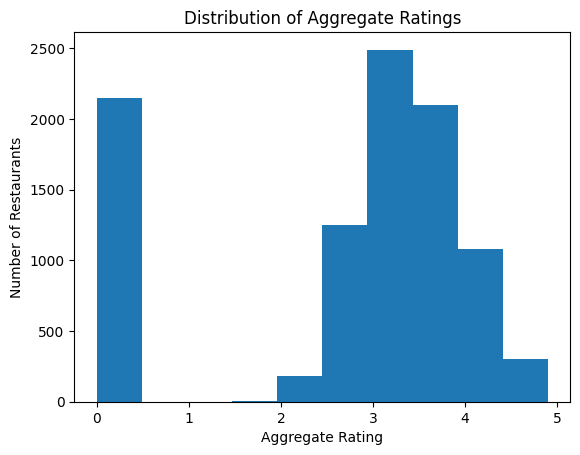

In [ ]:
import matplotlib.pyplot as plt
df["Aggregate rating"].plot(kind="hist",bins=10)
plt.title("Distribution of Aggregate Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")

plt.show()

In [ ]:
avg_vote=df["Votes"].mean()
print(avg_vote)

156.909747670401


Task_2: Cuisine Combination
Identify the most common combinations of
cuisines in the dataset.
Determine if certain cuisine combinations
tend to have higher ratings

In [ ]:
common_cuisine=df["Cuisines"].value_counts().head(5)
print(common_cuisine)

Cuisines
North Indian             936
North Indian, Chinese    511
Chinese                  354
Fast Food                354
North Indian, Mughlai    334
Name: count, dtype: int64


In [ ]:
high_rateing=df.groupby("Cuisines")["Aggregate rating"].mean()
most_rated=high_rateing.sort_values(ascending=False).head(5)
print(most_rated)

Cuisines
Burger, Bar Food, Steak            4.9
American, Burger, Grill            4.9
American, Caribbean, Seafood       4.9
American, Coffee and Tea           4.9
Mexican, American, Healthy Food    4.9
Name: Aggregate rating, dtype: float64


Task_3: Geographic Analysis
Plot the locations of restaurants on a
map using longitude and latitude
coordinates.
Identify any patterns or clusters of
restaurants in specific areas.


In [ ]:
import folium
center=[df["Latitude"].mean(),df["Longitude"].mean()]

In [ ]:
restaurant_map = folium.Map(location=center,zoom_start=5)


In [ ]:
for i in range(100):
    folium.Marker(
        [df.iloc[i]["Latitude"], df.iloc[i]["Longitude"]]
    ).add_to(restaurant_map)

restaurant_map

Restaurants are concentrated in major cities, forming clusters in urban area

Task_4: Restaurant Chains
Identify if there are any restaurant chains
present in the dataset.
Analyze the ratings and popularity of
different restaurant chains.


In [ ]:
chained_resturant=df["Restaurant Name"].value_counts()
print(chained_resturant)

Restaurant Name
Cafe Coffee Day             83
Domino's Pizza              79
Subway                      63
Green Chick Chop            51
McDonald's                  48
                            ..
HotMess                      1
Healthy Routes               1
Fuji Japanese Restaurant     1
Fa Yian                      1
Unplugged Courtyard          1
Name: count, Length: 7446, dtype: int64


Several restaurant chains appear multiple times in the dataset.

In [ ]:
avg_rating=df.groupby("Restaurant Name")["Aggregate rating"].mean()
avg_rating.sort_values(ascending=False).head(10)

,Aggregate rating
Restaurant Name,
Solita,4.9
Spiral - Sofitel Philippine Plaza Manila,4.9
Flat Iron,4.9
Sagar Gaire Fast Food,4.9
Bao,4.9
Yellow Dog Eats,4.9
Gaga Manjero,4.9
Sushi Masa,4.9
Shorts Burger and Shine,4.9


In [ ]:
avg_voting=df.groupby("Restaurant Name")["Votes"].mean()
avg_voting.sort_values(ascending=False).head(10)

,Votes
Restaurant Name,
Toit,10934.0
Hauz Khas Social,7931.0
Peter Cat,7574.0
Big Brewsky,5705.0
The Black Pearl,5385.0
BarBQ,5288.0
Warehouse Cafe,4914.0
Truffles,4841.0
Mocambo,4464.0


In [ ]:
# Votes: all restaurants vs rated only
print("Avg votes (all):", df["Votes"].mean())
print("Avg votes (rated only):", df_rated["Votes"].mean())

# Most common rating range (rated only)
print(pd.cut(df_rated["Aggregate rating"], bins=[0,2,2.5,3,3.5,4,4.5,5]).value_counts().sort_index())

# Top cuisine combinations by rating (20+ rated restaurants)
cs = df_rated.groupby("Cuisines")["Aggregate rating"].agg(["mean","count"])
print(cs[cs["count"] >= 20].sort_values("mean", ascending=False).head(5))

# Chains with 5+ rated outlets
ch = df_rated.groupby("Restaurant Name").agg(avg_rating=("Aggregate rating","mean"),
                                             avg_votes=("Votes","mean"),
                                             outlets=("Restaurant ID","count"))
ch = ch[ch["outlets"] >= 5]
print(ch.sort_values("avg_rating", ascending=False).head(5))
print(ch.sort_values("avg_votes", ascending=False).head(5))

Avg votes (all): 156.909747670401
Avg votes (rated only): 202.1850601107659
Aggregate rating
(0.0, 2.0]      10
(2.0, 2.5]     286
(2.5, 3.0]    1605
(3.0, 3.5]    2502
(3.5, 4.0]    1886
(4.0, 4.5]     908
(4.5, 5.0]     206
Name: count, dtype: int64
                    mean  count
Cuisines                       
Italian         3.950000     50
American        3.920690     29
Mexican         3.850000     34
Italian, Pizza  3.795652     23
Continental     3.745000     20
                 avg_rating    avg_votes  outlets
Restaurant Name                                  
Chili's            4.580000  1631.200000        5
Farzi Cafe         4.366667  1683.000000        6
Barbeque Nation    4.353846  1082.384615       26
Punjab Grill       4.340000  1084.800000        5
Mocha              4.185714   444.428571        7
                 avg_rating    avg_votes  outlets
Restaurant Name                                  
Farzi Cafe         4.366667  1683.000000        6
Chili's            4.580

**Conclusion of the extension: Excluding unrated restaurants raises average votes from 157 to 202. Most rated restaurants fall in the 3.0 to 3.5 range (34%). Using minimum sizes (20+ restaurants per cuisine, 5+ outlets per chain) replaces one-restaurant 4.9 averages with more reliable results: Italian (3.95) is the top-rated cuisine, and Barbeque Nation (4.35 across 26 outlets) is the strongest large chain**.